# E-Commerce Sales & Customer Analysis
**Goal:** understand what drives sales and profit, which products and discounts lose money, and which customers are most valuable (RFM segmentation).

**Data:** Sample Superstore orders, 2015-2018 (public dataset, 9,994 order lines). The raw file has two extra tables (Returns, People) pasted below the orders - I split and clean them first.
**Tools:** Python (Pandas, Matplotlib, Seaborn), Excel dashboard (see README).

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import matplotlib.ticker as mt
sns.set_theme(style='whitegrid'); plt.rcParams['figure.dpi']=110
raw = pd.read_csv('Superstore-raw.csv', encoding='latin1', dtype=str)
print(raw.shape)
raw.iloc[[0, 9993, 9994, 9995, 9999, 10000]].iloc[:, :4]

(10800, 21)


,Row ID,Order ID,Order Date,Ship Date
0,1,CA-2017-152156,11/8/2017,11/11/2017
9993,9994,CA-2018-119914,5/4/2018,5/9/2018
9994,Person,Region,NaN,NaN
9995,Anna Andreadi,West,NaN,NaN
9999,Returned,Order ID,NaN,NaN
10000,Yes,CA-2015-100762,NaN,NaN


## 1. Data quality checks and cleaning
The file has 10,800 rows, but only the first 9,994 are orders. Rows below them are two separate lookup tables that were pasted into the same sheet (a *People* table of regional managers and a *Returns* table of returned order IDs). They show up as ~15K missing values if you load the file naively.

In [2]:
orders  = raw.iloc[:9994].copy()
people  = raw.iloc[9995:9999, :2].set_axis(['Manager','Region'], axis=1)
returns = raw.iloc[10000:, :2].set_axis(['Returned','Order ID'], axis=1)
print('Returns rows:', len(returns), '| unique returned orders:', returns['Order ID'].nunique())

for c in ['Sales','Quantity','Discount','Profit']:
    orders[c] = pd.to_numeric(orders[c])
orders['Postal Code'] = orders['Postal Code'].astype(float)
orders['Order Date'] = pd.to_datetime(orders['Order Date'], format='%m/%d/%Y')
orders['Ship Date']  = pd.to_datetime(orders['Ship Date'],  format='%m/%d/%Y')

dups = orders.duplicated(subset=[c for c in orders.columns if c!='Row ID'])
print('Duplicate order lines:', dups.sum())
orders = orders[~dups].copy()
print('Missing values:', orders.drop(columns='Postal Code').isna().sum().sum(), '| Missing postal codes:', orders['Postal Code'].isna().sum(), '(Burlington, VT)')
print('Ship date before order date:', (orders['Ship Date'] < orders['Order Date']).sum())
print('Final:', orders.shape, '| orders:', orders['Order ID'].nunique(), '| customers:', orders['Customer ID'].nunique())

Returns rows: 800 | unique returned orders: 296
Duplicate order lines: 1
Missing values: 0 | Missing postal codes: 11 (Burlington, VT)
Ship date before order date: 0
Final: (9993, 21) | orders: 5009 | customers: 793


**Fixes:** split the embedded tables, converted text to numbers/dates, removed 1 duplicate order line. 11 postal codes are blank (all Burlington, VT) - left as is since postal code isn't used in the analysis.

In [3]:
# Join with Returns and People tables
returned_ids = set(returns['Order ID'])
orders['Returned'] = orders['Order ID'].isin(returned_ids)
orders = orders.merge(people, on='Region', how='left')
orders['Year']  = orders['Order Date'].dt.year
orders['Month'] = orders['Order Date'].dt.to_period('M').dt.to_timestamp()
orders['Margin'] = orders.Profit / orders.Sales
orders.to_csv('superstore_clean.csv', index=False)
orders.head(3)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Product Name,Sales,Quantity,Discount,Profit,Returned,Manager,Year,Month,Margin
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Bush Somerset Collection Bookcase,261.96,2,0.0,41.9136,False,Cassandra Brandow,2017,2017-11-01,0.16
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.0,219.5820,False,Cassandra Brandow,2017,2017-11-01,0.30
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.0,6.8714,False,Anna Andreadi,2017,2017-06-01,0.47


## 2. Headline KPIs

In [4]:
order_sales = orders.groupby('Order ID').Sales.sum()
print(f"Total sales : ${orders.Sales.sum():,.0f}")
print(f"Total profit: ${orders.Profit.sum():,.0f}  (margin {orders.Profit.sum()/orders.Sales.sum():.1%})")
print(f"Orders      : {orders['Order ID'].nunique():,} | Customers: {orders['Customer ID'].nunique():,}")
print(f"Avg order value: ${order_sales.mean():,.0f}")
yr = orders.groupby('Year').agg(Sales=('Sales','sum'), Profit=('Profit','sum'), Orders=('Order ID','nunique'))
yr['Margin %'] = (yr.Profit/yr.Sales*100).round(1); yr['Sales growth %'] = (yr.Sales.pct_change()*100).round(1)
yr.round(0).assign(**{'Margin %':yr['Margin %'], 'Sales growth %':yr['Sales growth %']})

Total sales : $2,296,919
Total profit: $286,409  (margin 12.5%)
Orders      : 5,009 | Customers: 793
Avg order value: $459


,Sales,Profit,Orders,Margin %,Sales growth %
Year,,,,,
2015,483966.0,49556.0,969,10.2,NaN
2016,470533.0,61619.0,1038,13.1,-2.8
2017,609206.0,81795.0,1315,13.4,29.5
2018,733215.0,93439.0,1687,12.7,20.4


## 3. Sales trend and seasonality

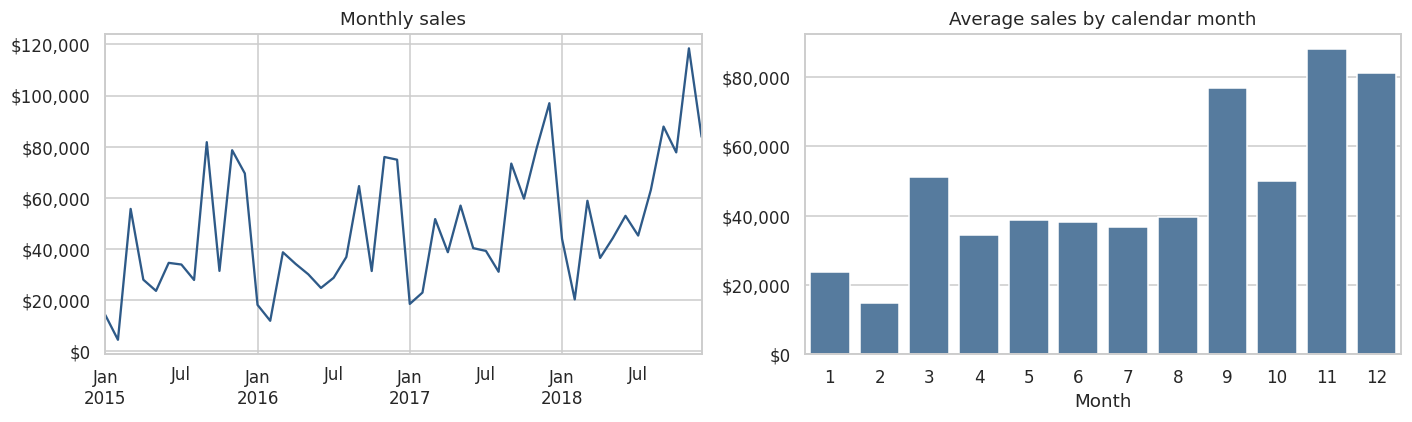

In [5]:
m = orders.groupby('Month').Sales.sum()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
m.plot(ax=ax[0], color='#2E5A88'); ax[0].set_title('Monthly sales'); ax[0].yaxis.set_major_formatter(mt.StrMethodFormatter('${x:,.0f}')); ax[0].set_xlabel('')
seas = m.groupby(m.index.month).mean()
sns.barplot(x=seas.index, y=seas.values, ax=ax[1], color='#4A7BAA'); ax[1].set_title('Average sales by calendar month'); ax[1].set_xlabel('Month'); ax[1].yaxis.set_major_formatter(mt.StrMethodFormatter('${x:,.0f}'))
plt.tight_layout(); plt.show()

Sales grew 29.5% in 2017 and 20.4% in 2018 after a small dip in 2016. There is strong seasonality: **September, November and December** are the biggest months (roughly 4x the Jan/Feb average).

## 4. Which products and categories make money?

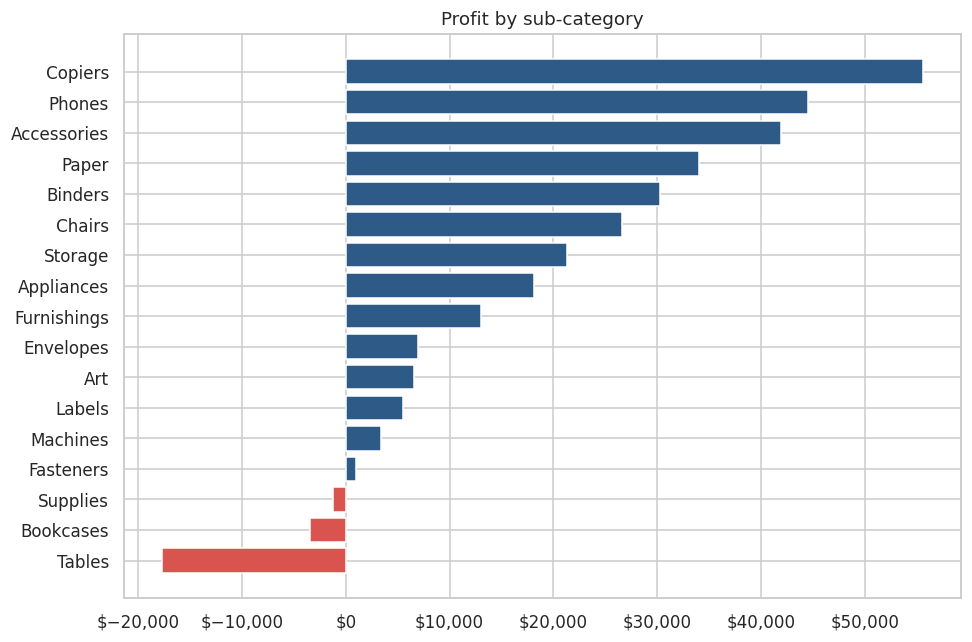

,Sales,Profit,Margin %
Sub-Category,,,
Copiers,149528.0,55618.0,37.2
Phones,330007.0,44516.0,13.5
Accessories,167380.0,41937.0,25.1
Paper,78479.0,34054.0,43.4
Binders,203413.0,30222.0,14.9
Chairs,328168.0,26602.0,8.1
Storage,223844.0,21279.0,9.5
Appliances,107532.0,18138.0,16.9
Furnishings,91705.0,13059.0,14.2


In [6]:
sub = orders.groupby('Sub-Category').agg(Sales=('Sales','sum'), Profit=('Profit','sum')).sort_values('Profit')
sub['Margin %'] = (sub.Profit/sub.Sales*100).round(1)
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(sub.index, sub.Profit, color=['#D9534F' if v<0 else '#2E5A88' for v in sub.Profit])
ax.set_title('Profit by sub-category'); ax.xaxis.set_major_formatter(mt.StrMethodFormatter('${x:,.0f}'))
plt.tight_layout(); plt.show()
sub.round(0).assign(**{'Margin %':sub['Margin %']}).iloc[::-1]

**Tables, Bookcases and Supplies lose money** (combined loss ~$22K). Tables alone have $207K in sales but a **-$17.7K profit**. Technology and Office Supplies earn most of the profit; Furniture is 32% of sales but only 6% of profit.

## 5. Discounts vs profit

,Lines,Sales,Profit,Margin %
Discount band,,,,
No discount,4798,1087908.0,320988.0,29.5
1-20%,3803,846522.0,100785.0,11.9
21-40%,459,233857.0,-35805.0,-15.3
Over 40%,933,128632.0,-99559.0,-77.4


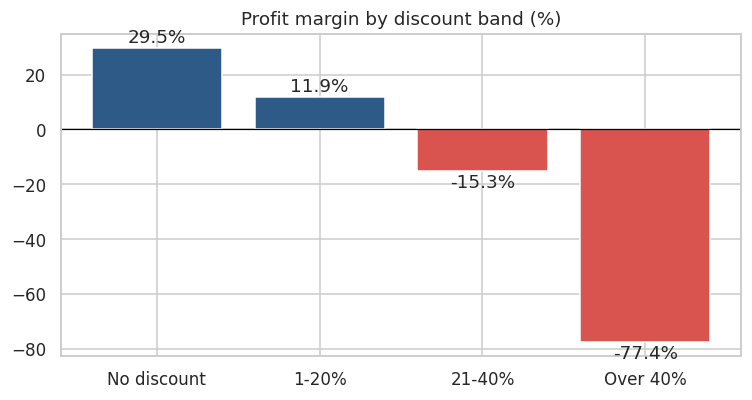

Lines with >20% discount: 1,392 (13.9% of lines) -> total profit $-135,364
Tables profit when discount <=20% vs >20%: {False: 12973.0, True: -30698.0}


In [7]:
orders['Discount band'] = pd.cut(orders.Discount, [-0.01, 0, 0.2, 0.4, 1], labels=['No discount','1-20%','21-40%','Over 40%'])
d = orders.groupby('Discount band', observed=True).agg(Lines=('Sales','size'), Sales=('Sales','sum'), Profit=('Profit','sum'))
d['Margin %'] = (d.Profit/d.Sales*100).round(1)
display(d.round(0).assign(**{'Margin %': d['Margin %']}))
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(d.index.astype(str), d['Margin %'], color=['#2E5A88' if v>0 else '#D9534F' for v in d['Margin %']])
ax.set_title('Profit margin by discount band (%)'); ax.axhline(0, color='black', lw=.8)
for i, v in enumerate(d['Margin %']): ax.text(i, v + (2 if v>0 else -6), f'{v}%', ha='center')
plt.tight_layout(); plt.show()
hi = orders[orders.Discount > 0.2]
print(f"Lines with >20% discount: {len(hi):,} ({len(hi)/len(orders):.1%} of lines) -> total profit ${hi.Profit.sum():,.0f}")
t = orders[orders['Sub-Category']=='Tables'].groupby(orders.Discount>0.2).Profit.sum().round(0)
print('Tables profit when discount <=20% vs >20%:', t.to_dict())

**Discounts above 20% destroy margin.** Items sold with no discount earn a 29.5% margin; 21-40% discounts lose 15%; over 40% lose 77%. The 1,392 lines discounted above 20% (13.9% of lines) lost $135K in total - *nearly half of the $286K total profit*. Tables are profitable at normal discounts (+$13.0K) but lose $30.7K when discounted above 20%.

## 6. Regions, states and returns (JOIN with Returns table)

In [8]:
reg = orders.groupby('Region').agg(Sales=('Sales','sum'), Profit=('Profit','sum'), Orders=('Order ID','nunique'))
reg['Margin %'] = (reg.Profit/reg.Sales*100).round(1)
reg['Returned orders'] = orders[orders.Returned].groupby('Region')['Order ID'].nunique()
reg['Return rate %'] = (reg['Returned orders']/reg.Orders*100).round(1)
display(reg.round(0).assign(**{'Margin %':reg['Margin %'], 'Return rate %':reg['Return rate %']}))
tot = orders[orders.Returned]['Order ID'].nunique()
print(f"Overall: {tot} of {orders['Order ID'].nunique():,} orders returned ({tot/orders['Order ID'].nunique():.1%}); returned orders = {orders[orders.Returned].Sales.sum()/orders.Sales.sum():.1%} of sales")
st = orders.groupby('State').Profit.sum().sort_values()
print('\nWorst states by profit:'); print(st.head(5).round(0))

,Sales,Profit,Orders,Margin %,Returned orders,Return rate %
Region,,,,,,
Central,501240.0,39706.0,1175,7.9,39,3.3
East,678500.0,91535.0,1401,13.5,44,3.1
South,391722.0,46749.0,822,11.9,24,2.9
West,725458.0,108418.0,1611,14.9,189,11.7


Overall: 296 of 5,009 orders returned (5.9%); returned orders = 7.9% of sales

Worst states by profit:
State
Texas            -25729.0
Ohio             -16959.0
Pennsylvania     -15560.0
Illinois         -12608.0
North Carolina    -7491.0
Name: Profit, dtype: float64


The **West region has an 11.7% return rate vs ~3% in every other region** - worth investigating (product quality, carrier or a data-recording difference). Overall 5.9% of orders were returned, covering 7.9% of sales. Texas, Ohio, Pennsylvania and Illinois all lose money.

## 7. Customer segmentation with RFM

In [9]:
snapshot = orders['Order Date'].max() + pd.Timedelta(days=1)
rfm = orders.groupby('Customer ID').agg(Customer=('Customer Name','first'), Segment_type=('Segment','first'),
        LastOrder=('Order Date','max'), Frequency=('Order ID','nunique'), Monetary=('Sales','sum'))
rfm['Recency'] = (snapshot - rfm.LastOrder).dt.days
rfm['R'] = pd.qcut(rfm.Recency, 5, labels=[5,4,3,2,1]).astype(int)             # recent = 5
rfm['F'] = pd.qcut(rfm.Frequency.rank(method='first'), 5, labels=[1,2,3,4,5]).astype(int)
rfm['M'] = pd.qcut(rfm.Monetary, 5, labels=[1,2,3,4,5]).astype(int)

def segment(x):
    fm = (x.F + x.M) / 2
    if x.R >= 4 and fm >= 4: return 'Champions'
    if x.R >= 3 and fm >= 3.5: return 'Loyal Customers'
    if x.R >= 4 and fm < 3: return 'New / Promising'
    if x.R <= 2 and fm >= 4: return "Can't Lose Them"
    if x.R <= 2 and fm >= 3: return 'At Risk'
    if x.R <= 2: return 'Hibernating'
    return 'Need Attention'
rfm['RFM Segment'] = rfm.apply(segment, axis=1)
seg = rfm.groupby('RFM Segment').agg(Customers=('Monetary','size'), Revenue=('Monetary','sum'), AvgRecency=('Recency','mean'), AvgOrders=('Frequency','mean'))
seg['% of customers'] = (seg.Customers/seg.Customers.sum()*100).round(1)
seg['% of revenue'] = (seg.Revenue/seg.Revenue.sum()*100).round(1)
seg = seg.sort_values('Revenue', ascending=False)
rfm.reset_index().to_csv('rfm_customers.csv', index=False)
seg.round(1)

,Customers,Revenue,AvgRecency,AvgOrders,% of customers,% of revenue
RFM Segment,,,,,,
Champions,135,686654.0,25.5,9.1,17.0,29.9
Loyal Customers,121,476296.4,60.9,7.8,15.3,20.7
Can't Lose Them,66,354996.5,222.0,8.5,8.3,15.5
Need Attention,127,241989.4,58.6,5.4,16.0,10.5
At Risk,65,214805.7,248.5,6.4,8.2,9.4
Hibernating,185,212440.2,355.6,4.0,23.3,9.2
New / Promising,94,109737.2,25.0,4.5,11.9,4.8


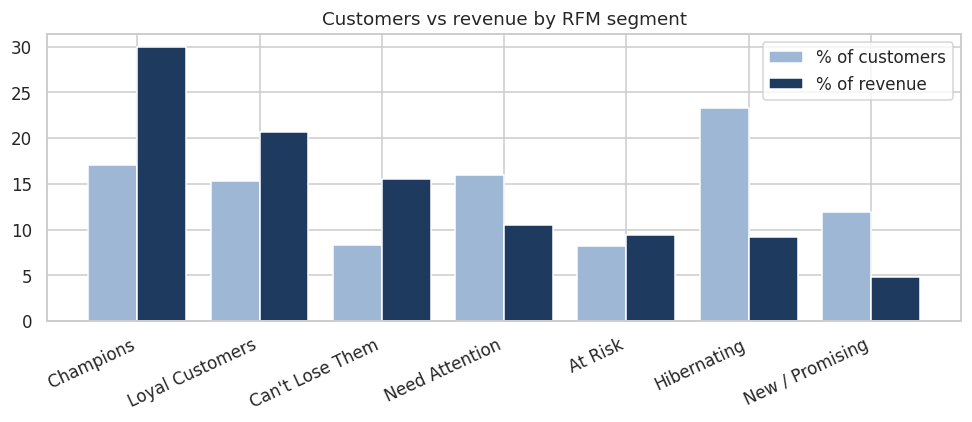

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(seg)); w = 0.4
ax.bar(x-w/2, seg['% of customers'], w, label='% of customers', color='#9DB7D5')
ax.bar(x+w/2, seg['% of revenue'], w, label='% of revenue', color='#1F3A5F')
ax.set_xticks(x); ax.set_xticklabels(seg.index, rotation=25, ha='right'); ax.legend(); ax.set_title('Customers vs revenue by RFM segment')
plt.tight_layout(); plt.show()

**Scoring:** Recency (days since last order, as of 31 Dec 2018), Frequency (number of orders) and Monetary (total sales) were each scored 1-5 by quintile, then combined into segments with simple rules (defined in `segment()` above).

**Findings:**
- **Champions are 17% of customers but 29.9% of revenue** ($687K).
- **"Can't Lose Them"** (high-value customers who have not ordered recently) are 66 customers = **15.5% of revenue** ($355K). With **At Risk** (9.4%), that is ~25% of revenue at risk of lapsing.
- **Hibernating** customers are 23.3% of customers but only 9.2% of revenue - low priority for spend.

## 8. Key findings and recommendations
1. **Sales are growing** (+29.5% in 2017, +20.4% in 2018) with a stable ~12.5% profit margin, and peak in Sep, Nov and Dec - plan stock and campaigns around them.
2. **Cap discounts at 20%.** Discounts above 20% (13.9% of lines) lost $135K - about 47% of total profit. Review Tables, Bookcases and Supplies pricing first.
3. **Run a win-back campaign** for "Can't Lose Them" and "At Risk" customers (131 customers, ~25% of revenue).
4. **Protect Champions** (17% of customers, 29.9% of revenue) with loyalty perks and early access.
5. **Investigate the West region's 11.7% return rate** (vs ~3% elsewhere).

*Caveat: this is a sample dataset; findings illustrate the analysis approach.*